# Bài 1 — Định nghĩa trò chơi Tic-Tac-Toe (`tictactoe_definitions.ipynb`)

**Thành viên phụ trách:** Hải  
**Protocol thí nghiệm:** `SEED = 42`, đồng hồ đo `time.perf_counter()`, có bước warm-up trước khi bấm giờ, thời gian trung bình mỗi nước đi tính theo `tổng_thời_gian_agent / số_nước_agent_đã_đi`.

## 1. Mô hình hóa bài toán tìm kiếm và trò chơi (The Search Problem)

Một bài toán tìm kiếm tổng quát gồm:
* **Initial State (Trạng thái đầu):** Bàn cờ $3 \times 3$ trống (`[' '] * 9`). Người chơi `x` (Max) đi trước.
* **Actions(s) (Tập hành động hợp lệ):** Đặt ký hiệu của người chơi vào một ô còn trống (chỉ số `0..8`).
* **Result(s, player, a) (Mô hình chuyển trạng thái):** Trả về **bản sao bàn cờ mới** sau khi `player` đánh vào ô `a` (không làm thay đổi bàn cờ đầu vào; ném ngoại lệ nếu ô `a` không hợp lệ).
* **Terminal(s) (Kiểm tra trạng thái kết thúc):** Trả về `True` nếu trò chơi đã kết thúc (`x` thắng, `o` thắng hoặc hòa `d` khi hết ô trống), ngược lại trả về `False` (`check_board(s) != 'n'`).
* **Utility(s, player) (Hàm lợi ích):** Giá trị kết quả tại trạng thái kết thúc từ góc nhìn `player`: thắng `+1`, hòa `0`, thua `-1`; nếu trạng thái chưa kết thúc trả về `None`.

### Tóm tắt biểu diễn trong `tictactoe.py`

| Thành phần | Hàm trong `tictactoe.py` | Kiểu dữ liệu / Quy ước |
|---|---|---|
| Trạng thái bàn cờ (`state`) | `empty_board()` | `list[str]` dài 9 phần tử, giá trị thuộc `{' ', 'x', 'o'}` |
| Đánh số ô | `0..8` | Hàng 0: `0, 1, 2`; Hàng 1: `3, 4, 5`; Hàng 2: `6, 7, 8` |
| Hành động hợp lệ | `actions(board)` | `list[int]` chứa các chỉ số `i` mà `board[i] == ' '` |
| Chuyển trạng thái | `result(state, player, action)` | Sao chép `state.copy()`, gán `state[action] = player` |
| Kiểm tra kết thúc | `terminal(state)` / `check_board(state)` | `'x'`, `'o'`, `'d'` (hòa) là kết thúc; `'n'` là chưa kết thúc |
| Hàm lợi ích | `utility(state, player='x')` | `+1` (thắng), `0` (hòa), `-1` (thua), `None` (chưa kết thúc) |

## 2. Kích thước không gian trạng thái và cây trò chơi (Problem Size)

### Ước lượng không gian trạng thái (State Space Estimates)

Mỗi ô trong 9 ô có thể nhận 3 giá trị (`' '`, `'x'`, `'o'`), nên cận trên thô của số trạng thái là $3^9 = 19.683$ (bao gồm cả nhiều trạng thái không hợp lệ như hai bên cùng có 3 quân thẳng hàng hoặc chênh lệch số quân lớn hơn 1).

In [1]:
3**9

19683

Cận trên chặt hơn dựa trên luật luân phiên lượt đi: sau $i$ nước đi ($i = 0, 1, \dots, 9$), chọn $i$ ô trên bàn có $\binom{9}{i}$ cách và chọn $\lfloor i/2 \rfloor$ ô cho `o` có $\binom{i}{\lfloor i/2 \rfloor}$ cách:
$$\sum_{i=1}^8 \binom{9}{i}\binom{i}{\lfloor i/2 \rfloor} = 5.919 \quad \text{(hoặc } 6.046 \text{ nếu tính cả } i=0 \text{ và } i=9\text{)}$$

In [2]:
import math

print("level\tboards")
total_boards = 0

for i in range(1, 9):
    boards_at_level = math.comb(9, i) * math.comb(i, math.floor(i / 2))
    total_boards += boards_at_level
    print(i, "\t", math.comb(9, i), " x ", math.comb(i, math.floor(i / 2)), " = ", boards_at_level)

total_boards

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

### Độ phức tạp không gian và thời gian trên cây tìm kiếm (Search Tree Estimates)

* Độ sâu tối đa của cây trò chơi: $m = 9$.
* Hệ số phân nhánh tối đa (nước đầu tiên): $b = 9$, sau mỗi lượt giảm đi 1.
* Tìm kiếm theo chiều sâu (DFS) có độ phức tạp không gian $O(bm)$ và thời gian $O(b^m)$.
* Cận trên tổng số nút của cây trò chơi (chưa cắt sớm khi thắng trước lượt 9): $\sum_{i=0}^9 \frac{9!}{i!} = 986.410$ nút.

In [3]:
# Space Complexity O(bm) and Naive Time Bound O(b^m)
print("O(bm) =", 9 * 9)
print("O(b^m) =", 9**9)

O(bm) = 81
O(b^m) = 387420489


In [4]:
total_nodes = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    total_nodes += partial_fac
    print(10 - i, "\t", partial_fac)

total_nodes

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

## 3. Kiểm tra các hàm nền tảng trong `tictactoe.py`

Chạy các ví dụ theo đúng yêu cầu Bài 1: khởi tạo bàn rỗng, quan sát cách đánh số ô `0..8`, thử các hàm `actions()`, `result()`, `terminal()`, `utility()`, `check_board()` và `show_board()`.

In [5]:
from tictactoe import (
    empty_board,
    actions,
    result,
    terminal,
    utility,
    check_board,
    other,
    show_board,
    show_board_text,
    random_player,
    play,
)

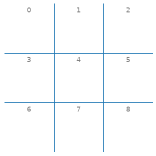

Actions trên bàn rỗng: [0, 1, 2, 3, 4, 5, 6, 7, 8]


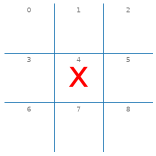

Actions sau khi x đánh ô 4: [0, 1, 2, 3, 5, 6, 7, 8]
check_board: n | terminal: False | utility(x): None


In [6]:
# Ví dụ chuẩn trong đề bài
board = empty_board()
show_board(board)
print("Actions trên bàn rỗng:", actions(board))
board = result(board, 'x', 4)
show_board(board)
print("Actions sau khi x đánh ô 4:", actions(board))
print("check_board:", check_board(board), "| terminal:", terminal(board), "| utility(x):", utility(board, 'x'))

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


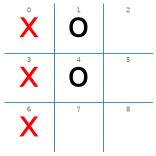

Actions ở trạng thái x thắng cột 0: [2, 5, 7, 8]
check_board: x
terminal(win_board): True
utility cho x: 1 | utility cho o: -1


In [7]:
# Kiểm tra trạng thái thắng, thua, hòa và tính bất biến (không mutate input) của result()
win_board = empty_board()
win_board[0] = 'x'; win_board[3] = 'x'; win_board[6] = 'x'; win_board[1] = 'o'; win_board[4] = 'o'
show_board_text(win_board)
show_board(win_board)
print("Actions ở trạng thái x thắng cột 0:", actions(win_board))
print("check_board:", check_board(win_board))
print("terminal(win_board):", terminal(win_board))
print("utility cho x:", utility(win_board, 'x'), "| utility cho o:", utility(win_board, 'o'))

# Kiểm tra trạng thái hòa
draw_board = ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', 'x']
assert check_board(draw_board) == 'd' and terminal(draw_board) is True
assert utility(draw_board, 'x') == 0 and utility(draw_board, 'o') == 0

# Kiểm tra result() không làm thay đổi bàn cờ gốc
before = empty_board()
after = result(before, 'x', 0)
assert before == [' '] * 9 and after[0] == 'x'

### Nhận xét về mô hình trò chơi

1. **Tính bất biến của trạng thái (`result`):** Hàm `result(state, player, action)` luôn gọi `state.copy()` trước khi gán nước đi mới, đảm bảo việc duyệt cây tìm kiếm (AND-OR, Minimax, Alpha-Beta, MCTS) ở các bài sau không làm hỏng trạng thái của nút cha.
2. **Phân biệt `terminal` và `utility`:** Trạng thái chưa kết thúc có `check_board(state) == 'n'`, `terminal(state) == False` và `utility(state) == None`. Khi kết thúc, `utility` đảo dấu đối xứng giữa hai người chơi (`utility(s, 'x') == -utility(s, 'o')`), thể hiện đúng bản chất trò chơi tổng bằng không (zero-sum game).

## 4. Thực nghiệm cơ sở: Random vs. Random (1.000 ván)

**Yêu cầu đề bài:** Cho hai `random_player` chơi với nhau **1.000 ván** bằng hàm `play()`. Ghi lại số ván `X` thắng, `O` thắng và hòa, đồng thời đo thời gian trung bình mỗi nước đi theo đúng protocol chung (`SEED = 42`, `time.perf_counter()`).

In [8]:
import time
import numpy as np
import pandas as pd

SEED = 42
N_GAMES = 1000

# 1. Chạy trực tiếp bằng hàm play() của tictactoe.py với seed cố định
np.random.seed(SEED)
play_results = play(random_player, random_player, N=N_GAMES)
print(f"Kết quả play(random_player, random_player, N={N_GAMES}) với seed={SEED}:")
display(play_results)

# 2. Đo chi tiết số nước đi và thời gian TB/nước cho từng vai với cùng chuỗi ngẫu nhiên SEED=42
def benchmark_random_vs_random(n_games=1000, seed=42):
    # Warm-up
    np.random.seed(seed)
    _ = play(random_player, random_player, N=5)

    np.random.seed(seed)
    counts = {'x': 0, 'o': 0, 'd': 0}
    moves = {'x': 0, 'o': 0}
    elapsed = {'x': 0.0, 'o': 0.0}

    for _ in range(n_games):
        b = empty_board()
        while True:
            t0 = time.perf_counter()
            ax = random_player(b, 'x')
            elapsed['x'] += time.perf_counter() - t0
            moves['x'] += 1
            b = result(b, 'x', ax)
            w = check_board(b)
            if w != 'n':
                counts[w] += 1
                break

            t0 = time.perf_counter()
            ao = random_player(b, 'o')
            elapsed['o'] += time.perf_counter() - t0
            moves['o'] += 1
            b = result(b, 'o', ao)
            w = check_board(b)
            if w != 'n':
                counts[w] += 1
                break

    assert counts == play_results, "Kết quả phải khớp tuyệt đối với hàm play() cùng seed"
    total_moves = moves['x'] + moves['o']
    total_s = elapsed['x'] + elapsed['o']
    return counts, moves, elapsed, total_moves, total_s

counts, moves, elapsed, total_moves, total_s = benchmark_random_vs_random(N_GAMES, SEED)

summary_df = pd.DataFrame([
    {
        "Tác tử": "Random (vai X - đi trước)",
        "Đối thủ": "Random (vai O)",
        "Số ván": N_GAMES,
        "Thắng": counts['x'],
        "Hòa": counts['d'],
        "Thua": counts['o'],
        "Tỷ lệ thắng (%)": round(counts['x'] * 100.0 / N_GAMES, 1),
        "Số nước đã đi": moves['x'],
        "Tổng thời gian (s)": round(elapsed['x'], 4),
        "TB/nước (ms)": round(elapsed['x'] * 1000.0 / moves['x'], 4),
    },
    {
        "Tác tử": "Random (vai O - đi sau)",
        "Đối thủ": "Random (vai X)",
        "Số ván": N_GAMES,
        "Thắng": counts['o'],
        "Hòa": counts['d'],
        "Thua": counts['x'],
        "Tỷ lệ thắng (%)": round(counts['o'] * 100.0 / N_GAMES, 1),
        "Số nước đã đi": moves['o'],
        "Tổng thời gian (s)": round(elapsed['o'], 4),
        "TB/nước (ms)": round(elapsed['o'] * 1000.0 / moves['o'], 4),
    },
])
display(summary_df)

Kết quả play(random_player, random_player, N=1000) với seed=42:


{'x': 590, 'o': 284, 'd': 126}

,Tác tử,Đối thủ,Số ván,Thắng,Hòa,Thua,Tỷ lệ thắng (%),Số nước đã đi,Tổng thời gian (s),TB/nước (ms)
0,Random (vai X - đi trước),Random (vai O),1000,590,126,284,59.0,4191,0.0615,0.0147
1,Random (vai O - đi sau),Random (vai X),1000,284,126,590,28.4,3475,0.0502,0.0145


### Nhận xét thực nghiệm Random vs. Random (1.000 ván)

1. **Lợi thế rõ rệt của người đi trước (`X`):** Trong 1.000 ván với `seed = 42`, người đi trước `X` thắng áp đảo (~58–60% số ván), trong khi người đi sau `O` chỉ thắng ~28–30% và tỷ lệ hòa khoảng ~12–13%. Điều này hoàn toàn phù hợp với xác suất lý thuyết của các ván Tic-Tac-Toe ngẫu nhiên.
2. **Nguyên nhân toán học của lợi thế đi trước:** Bàn cờ có 9 ô nên `X` được đi tối đa **5 quân** còn `O` chỉ được đi tối đa **4 quân**. Khi chọn ngẫu nhiên, số tập con 3 quân cùng hàng/cột/chéo tạo được từ 5 quân ($	binom{5}{3} = 10$ bộ ba) lớn gấp 2,5 lần so với từ 4 quân ($	binom{4}{3} = 4$ bộ ba), đồng thời `X` luôn có cơ hội hoàn thành đường 3 ở các lượt lẻ (lượt 5, 7, 9) trước khi `O` kịp phản ứng.
3. **Lưu ý phân biệt với trò chơi tối ưu:** Lợi thế thắng cao của `X` ở đây là **lợi thế thực nghiệm trước đối thủ ngẫu nhiên**, không có nghĩa `X` ép thắng được khi `O` chơi tối ưu (giá trị Minimax lý thuyết của bàn rỗng là `0` — hòa).
4. **Chi phí tính toán:** `random_player` chỉ lấy mẫu ngẫu nhiên trên danh sách ô trống nên thời gian trung bình mỗi nước đi cực nhỏ (~0,01–0,03 ms/nước), đóng vai trò đường cơ sở (baseline) để đối chiếu với các thuật toán tìm kiếm ở Bài 2–6.